# 01 — Análisis exploratorio de datos

Lectura automática de medidores de agua — Visión por Computadora II (CEIA, FIUBA).

Se analizan los tres conjuntos de datos del proyecto:

| Dataset | Uso |
|---|---|
| Toloka Water Meters | Entrenamiento de la segmentación del visor |
| water-meter-dataset v3 (Roboflow) | Entrenamiento de la detección de dígitos |
| Fotos de campo CEML | Prueba en condiciones reales |

**Ejecución:** funciona en local (desde la carpeta `notebooks/`) y en Google Colab. En Colab, cargar la API key de Roboflow como *Secret* con el nombre `ROBOFLOW_API_KEY`.

In [1]:
# Configuración del entorno: local o Google Colab.
import os
import sys
import subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/martinlacheski/ceia-vpc-2.git"

if IN_COLAB:
    if not Path("ceia-vpc-2").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    os.chdir("ceia-vpc-2")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
    from google.colab import userdata
    try:
        os.environ["ROBOFLOW_API_KEY"] = userdata.get("ROBOFLOW_API_KEY")
    except Exception:
        print("Aviso: falta el Secret ROBOFLOW_API_KEY; no se podrá descargar water-meter-dataset.")
elif Path.cwd().name == "notebooks":
    # En local el notebook se abre desde notebooks/: se trabaja desde la raíz del repo.
    os.chdir("..")

print("Directorio de trabajo:", Path.cwd(), "| Colab:", IN_COLAB)

Directorio de trabajo: /home/martin/Code/ceia-vpc-2 | Colab: False


In [2]:
# Descarga de los datasets públicos (si ya están en data/raw/, no se descarga nada).
result = subprocess.run([sys.executable, "scripts/download_data.py"], capture_output=True, text=True)
print(result.stdout, result.stderr)

Toloka ya está en data/raw/toloka
water-meter-dataset ya está en data/raw/roboflow_water_meter
 


In [3]:
import ast
import random
from collections import Counter

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

random.seed(42)
TOLOKA = Path("data/raw/toloka")
ROBOFLOW = Path("data/raw/roboflow_water_meter")
CEML = Path("data/ceml")


def display_geometry(points: np.ndarray, width: int, height: int) -> tuple[float, float]:
    """Devuelve (fracción del área de la imagen, inclinación del visor en grados 0-90).

    La inclinación es el ángulo del lado largo del rectángulo mínimo que contiene
    al polígono, medido respecto de la horizontal: 0 = visor horizontal, 90 = vertical.
    """
    area = cv2.contourArea(points.astype(np.float32)) / (width * height)
    (_, _), (w, h), angle = cv2.minAreaRect(points.astype(np.float32))
    if w < h:
        angle += 90
    angle = angle % 180
    return area, min(angle, 180 - angle)


def yolo_polygon(label: Path, width: int, height: int) -> np.ndarray:
    """Lee la primera línea de una etiqueta YOLO-seg y la pasa a píxeles."""
    values = list(map(float, label.read_text().split()[1:]))
    return np.array(values).reshape(-1, 2) * [width, height]

## 1. Toloka (segmentación del visor)

In [4]:
toloka = pd.read_csv(TOLOKA / "data.csv")
rows = []
for r in toloka.itertuples():
    with Image.open(TOLOKA / "images" / r.photo_name) as im:
        w, h = im.size
    pts = np.array([[p["x"] * w, p["y"] * h] for p in ast.literal_eval(r.location)["data"]])
    area, tilt = display_geometry(pts, w, h)
    # La lectura exacta está en el nombre: id_<n>_value_<entero>_<decimales>.jpg
    integer = r.photo_name.split("_value_")[1].split("_")[0]
    rows.append({"file": r.photo_name, "width": w, "height": h, "area": area, "tilt": tilt,
                 "integer_digits": len(integer)})
toloka_geo = pd.DataFrame(rows)
print(f"Imágenes: {len(toloka_geo)}")
print("Resoluciones más frecuentes:", Counter(zip(toloka_geo.width, toloka_geo.height)).most_common(3))
toloka_geo[["area", "tilt"]].describe().round(3)

Imágenes: 1244
Resoluciones más frecuentes: [((1000, 1333), 716), ((1333, 1000), 346), ((1778, 1000), 61)]


,area,tilt
count,1244.000,1244.000
mean,0.023,11.106
std,0.013,21.218
min,0.003,0.000
25%,0.013,1.141
50%,0.020,2.928
75%,0.028,8.036
max,0.150,90.000


## 2. Fotos de campo CEML (prueba en condiciones reales)

In [5]:
meta = pd.read_csv(CEML / "metadata.csv")
rows = []
for r in meta.itertuples():
    with Image.open(CEML / "images" / r.file) as im:
        w, h = im.size
    area, tilt = display_geometry(yolo_polygon(CEML / "labels" / f"{Path(r.file).stem}.txt", w, h), w, h)
    rows.append({"file": r.file, "width": w, "height": h, "area": area, "tilt": tilt})
ceml_geo = pd.DataFrame(rows)
print(f"Imágenes: {len(ceml_geo)} | medidores distintos: {meta.meter_id.nunique()}")
print("Fotos por mes:", meta.month.value_counts().sort_index().to_dict())
print("Fotos por ruta:", meta.route.value_counts().to_dict())
ceml_geo[["area", "tilt"]].describe().round(3)

Imágenes: 324 | medidores distintos: 314
Fotos por mes: {'2018-08': 19, '2018-09': 18, '2018-10': 20, '2018-11': 17, '2018-12': 19, '2019-01': 22, '2019-02': 20, '2019-03': 12, '2019-04': 27, '2019-05': 19, '2019-06': 19, '2019-07': 19, '2019-08': 13, '2019-09': 24, '2019-10': 22, '2019-11': 8, '2019-12': 26}
Fotos por ruta: {80: 163, 90: 161}


,area,tilt
count,324.000,324.000
mean,0.021,10.516
std,0.015,23.650
min,0.002,0.000
25%,0.011,0.874
50%,0.017,1.945
75%,0.026,4.772
max,0.107,90.000


## 3. Comparación de dominios: Toloka vs CEML

La inclinación del visor y su tamaño relativo en la imagen son las dos diferencias que más pueden afectar al pipeline: un visor inclinado complica la lectura de los dígitos (motiva la rectificación) y un visor chico complica la segmentación.

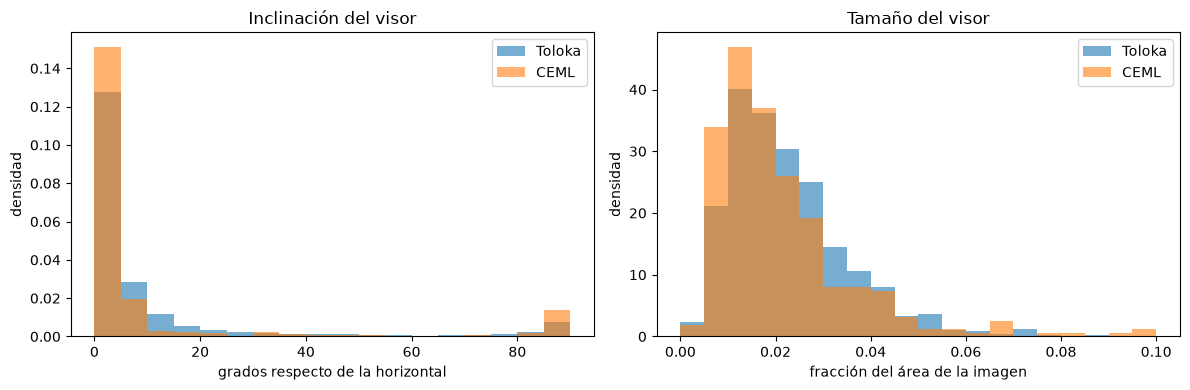

,Toloka,CEML
inclinación mediana (°),2.9,1.9
% visores inclinados > 15°,16.0,13.0
área mediana del visor (%),2.0,1.7


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins_tilt = np.linspace(0, 90, 19)
axes[0].hist(toloka_geo.tilt, bins=bins_tilt, alpha=0.6, density=True, label="Toloka")
axes[0].hist(ceml_geo.tilt, bins=bins_tilt, alpha=0.6, density=True, label="CEML")
axes[0].set(title="Inclinación del visor", xlabel="grados respecto de la horizontal", ylabel="densidad")
axes[0].legend()

bins_area = np.linspace(0, 0.1, 21)
axes[1].hist(toloka_geo.area.clip(upper=0.1), bins=bins_area, alpha=0.6, density=True, label="Toloka")
axes[1].hist(ceml_geo.area.clip(upper=0.1), bins=bins_area, alpha=0.6, density=True, label="CEML")
axes[1].set(title="Tamaño del visor", xlabel="fracción del área de la imagen", ylabel="densidad")
axes[1].legend()
plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    "Toloka": [toloka_geo.tilt.median(), (toloka_geo.tilt > 15).mean() * 100, toloka_geo.area.median() * 100],
    "CEML": [ceml_geo.tilt.median(), (ceml_geo.tilt > 15).mean() * 100, ceml_geo.area.median() * 100],
}, index=["inclinación mediana (°)", "% visores inclinados > 15°", "área mediana del visor (%)"])
summary.round(1)

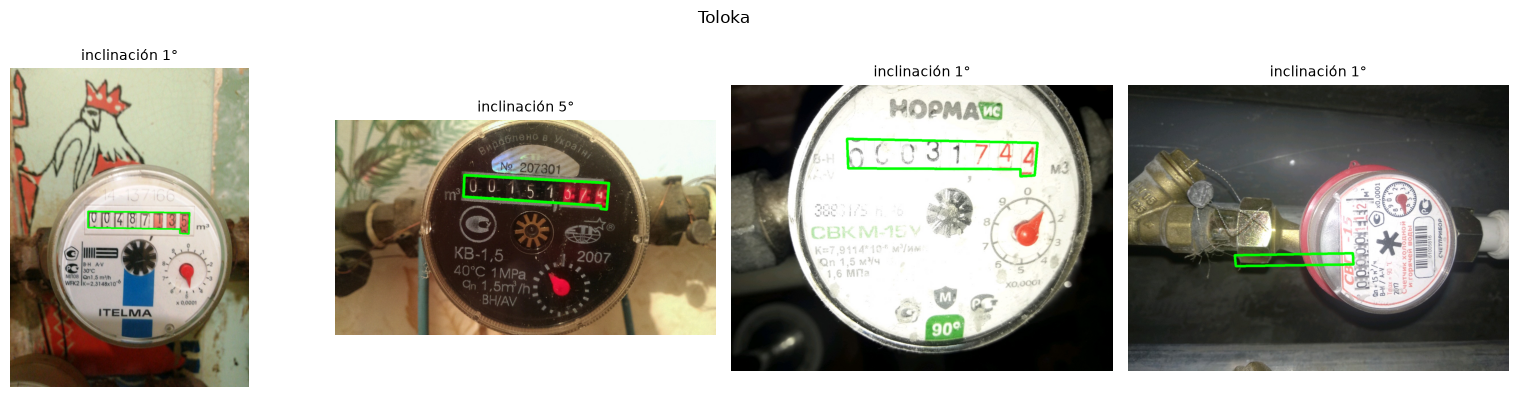

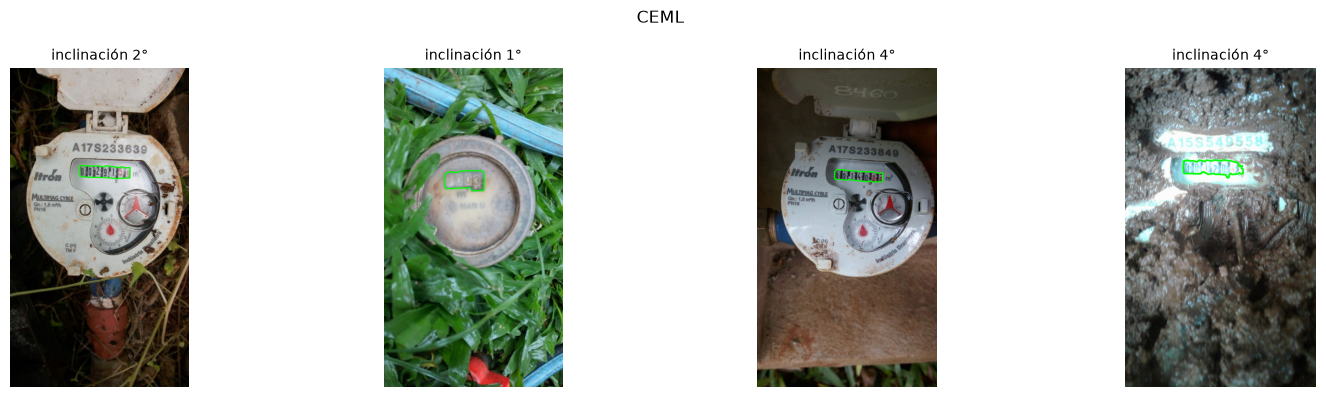

In [7]:
def show_samples(df, images_dir, polygon_fn, title, n=4):
    """Muestra n imágenes al azar con el polígono del visor superpuesto."""
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))
    for ax, r in zip(axes, df.sample(n, random_state=42).itertuples()):
        img = np.array(Image.open(images_dir / r.file).convert("RGB"))
        pts = polygon_fn(r).astype(np.int32)
        cv2.polylines(img, [pts], True, (0, 255, 0), max(3, img.shape[1] // 150))
        ax.imshow(img)
        ax.set_title(f"inclinación {r.tilt:.0f}°", fontsize=10)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


toloka_polys = {r.photo_name: ast.literal_eval(r.location)["data"] for r in toloka.itertuples()}
show_samples(toloka_geo, TOLOKA / "images",
             lambda r: np.array([[p["x"] * r.width, p["y"] * r.height] for p in toloka_polys[r.file]]),
             "Toloka")
show_samples(ceml_geo, CEML / "images",
             lambda r: yolo_polygon(CEML / "labels" / f"{Path(r.file).stem}.txt", r.width, r.height),
             "CEML")

## 4. water-meter-dataset v3 (detección de dígitos)

Imágenes por split: {'train': 7504, 'valid': 795, 'test': 679}


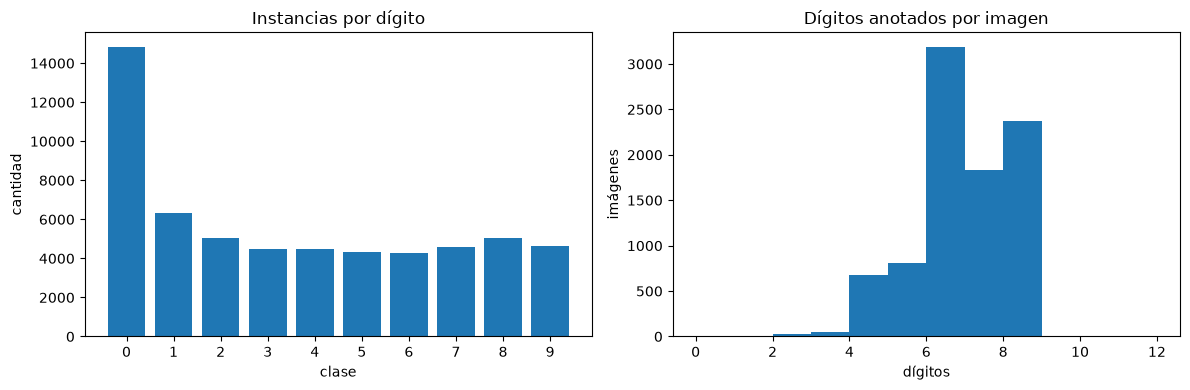

In [8]:
if not (ROBOFLOW / "data.yaml").exists():
    print("water-meter-dataset no está descargado: se omite esta sección.")
else:
    import yaml
    names = yaml.safe_load((ROBOFLOW / "data.yaml").read_text())["names"]
    split_counts, class_counts, digits_per_image = {}, Counter(), []
    for split in ("train", "valid", "test"):
        labels = list((ROBOFLOW / split / "labels").glob("*.txt"))
        split_counts[split] = len(labels)
        for label in labels:
            classes = [int(line.split()[0]) for line in label.read_text().splitlines() if line.strip()]
            class_counts.update(classes)
            digits_per_image.append(sum(names[c].isdigit() for c in classes))
    print("Imágenes por split:", split_counts)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    digit_ids = [i for i, n in enumerate(names) if n.isdigit()]
    axes[0].bar([names[i] for i in digit_ids], [class_counts[i] for i in digit_ids])
    axes[0].set(title="Instancias por dígito", xlabel="clase", ylabel="cantidad")
    axes[1].hist(digits_per_image, bins=range(0, 13))
    axes[1].set(title="Dígitos anotados por imagen", xlabel="dígitos", ylabel="imágenes")
    plt.tight_layout()
    plt.show()

## 5. Conclusiones

1. **La geometría del visor es similar en Toloka y CEML.** La inclinación mediana es de 2,9° y 1,9° respectivamente, y solo el 16% y el 13% de los visores supera los 15°. En ambos hay un grupo de visores verticales (cerca de 90°). La diferencia de dominio de CEML no está en la geometría sino en la **apariencia**: barro, reflejos, poca luz y tapas parcialmente cerradas.
2. **La rectificación aporta sobre todo en una minoría de casos.** Por eso el experimento A/B (recorte por caja vs. máscara + rectificación) debe reportarse **estratificado por inclinación** (≤ 15° y > 15°): un promedio global diluiría el efecto.
3. **El visor es un objeto pequeño:** ocupa una mediana del 2,0% (Toloka) y 1,7% (CEML) del área de la imagen. Esto justifica el pipeline en dos etapas: segmentar el visor primero y leer los dígitos sobre el recorte, en lugar de detectar dígitos sobre la imagen completa.
4. **El dígito 0 está sobrerrepresentado** (unas 3 veces más instancias que el resto) por los ceros a la izquierda de las lecturas. Conviene reportar métricas por clase en el detector de dígitos.
5. **Las lecturas tienen típicamente entre 6 y 8 dígitos** anotados por imagen, lo que permite validar la salida del pipeline por longitud.

*Limitación:* la inclinación se mide sobre el polígono y no distingue un visor invertido (180°) de uno derecho; ese caso se analiza en la etapa de lectura de dígitos.